In [1]:
from google.colab import drive

In [2]:
import os

In [11]:
PROJECT_PATH = ("/content/drive/MyDrive/malayalam-aspect-classification")
print(os.listdir('/content/drive/MyDrive'))
PROJECT_PATH = "/content/drive/MyDrive/malayalam-aspect-classification"

folders = [
    "dataset",
    "notebooks",
    "models",
    "results",
    "results/confusion_matrices",
    "src"
]

for folder in folders:
    path = os.path.join(PROJECT_PATH, folder)
    os.makedirs(path, exist_ok=True)

print("Project structure created successfully!")

print(os.listdir(PROJECT_PATH))

['malayalam-aspect-classification']
Project structure created successfully!
['models', 'notebooks', 'dataset', 'results', 'src']


In [4]:
DATASET_PATH = os.path.join(PROJECT_PATH,"dataset")
MODEL_PATH = os.path.join(PROJECT_PATH,"models")
RESULT_PATH = os.path.join(PROJECT_PATH,"results")
SRC_PATH = os.path.join(PROJECT_PATH,"src")

In [5]:
os.makedirs(MODEL_PATH,exist_ok=True)
os.makedirs(RESULT_PATH,exist_ok=True)
os.makedirs(SRC_PATH,exist_ok=True)
print("Project directory ready!")

Project directory ready!


In [6]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn openpyxl joblib iterative-stratification

In [7]:
import pandas as pd
import numpy as np
import re
import os
import json
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report,f1_score,precision_score,recall_score,hamming_loss)
print("All libaries imported successfully")

All libaries imported successfully


In [8]:
from google.colab import files
uploaded = files.upload()

Saving MABSA4000CSV.csv to MABSA4000CSV.csv


In [12]:
import shutil

filename = next(iter(uploaded))

destination = os.path.join(
    PROJECT_PATH,
    "dataset",
    "MABSA4000CSV.csv"
)

shutil.copy(filename, destination)

print("Dataset copied to Google Drive!")

Dataset copied to Google Drive!


In [13]:
import pandas as pd

file_path = os.path.join(
    PROJECT_PATH,
    "dataset",
    "MABSA4000CSV.csv"
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head(3))

Dataset shape: (4000, 12)

Columns:
['Unnamed: 0', 'Id', 'Review', 'Direction', 'Acting', 'Songs', 'Screenplay', 'Story', 'Camera', 'Casting', 'BGM', 'Editing']


,Unnamed: 0,Id,Review,Direction,Acting,Songs,Screenplay,Story,Camera,Casting,BGM,Editing
0,0,1,സന്തോഷ് പണ്ഡിറ്റ് ഈ ചിത്രത്തിലെ തന്റെ പ്രവർത്ത...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്...",0.5,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN
2,2,3,പാലക്കാട്‌ ഗ്രാമങ്ങളിലെ ഒരു കൺകെട്ട് മോശമായി ച...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
aspect_columns = [
    "Direction",
    "Acting",
    "Songs",
    "Screenplay",
    "Story",
    "Camera",
    "Casting",
    "BGM",
    "Editing"
]
for col in aspect_columns:
  print("\n" + "=" * 40)
  print("COLUMN:", col)
  print(df[col].value_counts(dropna=False))
  print("Unique values:")
  print(df[col].unique())


COLUMN: Direction
Direction
NaN    2824
1.0     554
0.0     532
0.5      90
Name: count, dtype: int64
Unique values:
[0.  0.5 nan 1. ]

COLUMN: Acting
Acting
NaN    2755
1.0     596
0.0     560
0.5      89
Name: count, dtype: int64
Unique values:
[nan 0.  1.  0.5]

COLUMN: Songs
Songs
NaN    3307
1.0     332
0.0     297
0.5      64
Name: count, dtype: int64
Unique values:
[nan 1.  0.  0.5]

COLUMN: Screenplay
Screenplay
NaN    3135
1.0     401
0.0     365
0.5      99
Name: count, dtype: int64
Unique values:
[nan 0.  1.  0.5]

COLUMN: Story
Story
NaN    3194
0.0     338
1.0     335
0.5     133
Name: count, dtype: int64
Unique values:
[nan 0.5 1.  0. ]

COLUMN: Camera
Camera
NaN    3012
1.0     471
0.0     427
0.5      90
Name: count, dtype: int64
Unique values:
[nan 0.  1.  0.5]

COLUMN: Casting
Casting
NaN    3147
0.0     411
1.0     401
0.5      41
Name: count, dtype: int64
Unique values:
[nan 1.  0.  0.5]

COLUMN: BGM
BGM
NaN    3549
1.0     208
0.0     188
0.5      55
Name: count, 

In [15]:
df = pd.read_csv(file_path)
df_clean = df.copy()
print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (4000, 12)
Working dataset: (4000, 12)


In [16]:
def preprocess_text(text):

    if pd.isna(text):
        return ""

    text = str(text)


    text = re.sub(
        r'https?://\S+|www\.\S+',
        '',
        text
    )


    text = re.sub(
        r'<[^>]+>',
        '',
        text
    )


    text = re.sub(
        r'\s+',
        ' ',
        text
    )

    return text.strip()


df_clean["Review"] = df_clean["Review"].apply(
    preprocess_text
)

print("Text preprocessing completed.")

display(df_clean[["Review"]].head(5))

Text preprocessing completed.


,Review
0,സന്തോഷ് പണ്ഡിറ്റ് ഈ ചിത്രത്തിലെ തന്റെ പ്രവർത്ത...
1,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്..."
2,പാലക്കാട്‌ ഗ്രാമങ്ങളിലെ ഒരു കൺകെട്ട് മോശമായി ച...
3,"വളരെ മികച്ച രീതിയിൽ ഉള്ള കഥയും, സംവിധാനവും. അഭ..."
4,തിരക്കഥ: തിരക്കഥ മോശമായി എഴുതിയതിനാൽ ഒരു സ്വാധ...


In [17]:
print("Rows before cleaning", len(df_clean))

df_clean = df_clean[df_clean["Review"].str.len()>0].copy()
df_clean = df_clean.drop_duplicates(subset=["Review"])
df_clean = df_clean.reset_index(drop=True)
print("Rows after cleaning:",len(df_clean))

Rows before cleaning 4000
Rows after cleaning: 3842


In [18]:
aspect_columns = [ "Direction","Acting","Songs","Screenplay","Story","Camera","Casting","BGM","Editing"]
aspect_values = df_clean[aspect_columns].apply(pd.to_numeric,errors="coerce")
allowed_values = {0.0,0.5,1.0}

for col in aspect_columns:
  unexpected = (set(aspect_values[col].dropna().unique())-allowed_values)
  if unexpected:
    raise ValueError(f"Unexpected values in {col}: {unexpected}")

Y = aspect_values.notna().astype(int)
X = df_clean ["Review"]
print("Input samples:", len(X))
print("Number of aspect labels:", Y.shape[1])
display(Y.head())

Input samples: 3842
Number of aspect labels: 9


,Direction,Acting,Songs,Screenplay,Story,Camera,Casting,BGM,Editing
0,1,0,0,0,0,0,0,0,0
1,1,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0
3,1,0,0,0,1,0,1,0,0
4,0,0,0,1,0,0,0,0,0


In [19]:
cleaned_path = os.path.join(PROJECT_PATH,"dataset","cleaned_mabsa.csv")
df_clean.to_csv(cleaned_path,index=False,encoding="utf-8-sig")
print("Cleaned dataset saved:", cleaned_path)

Cleaned dataset saved: /content/drive/MyDrive/malayalam-aspect-classification/dataset/cleaned_mabsa.csv


Aspect distribution


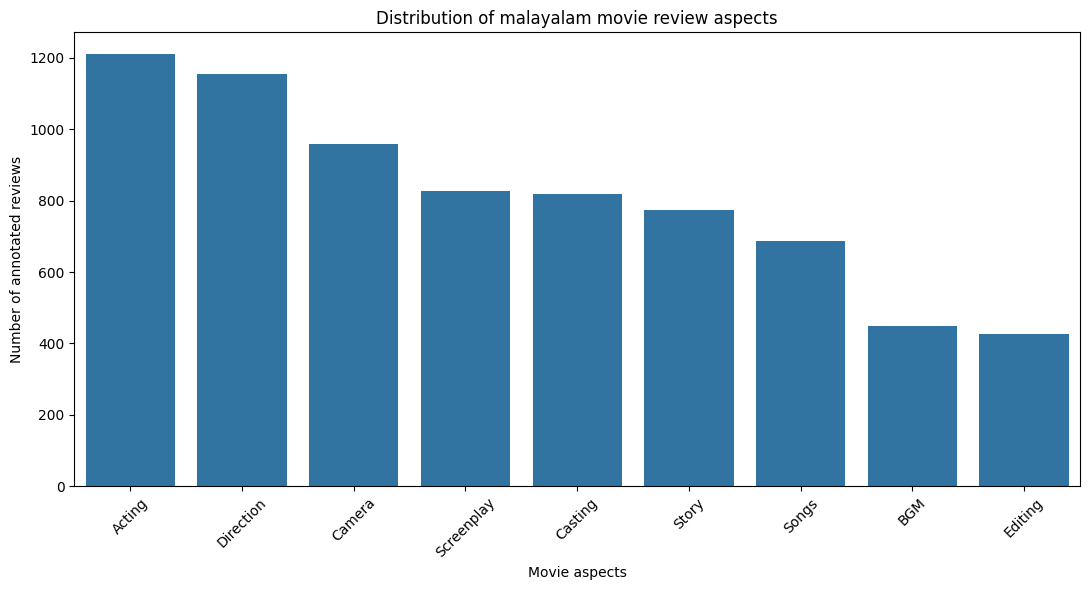

In [20]:
aspect_distribution = Y.sum().sort_values(ascending=False)
print("Aspect distribution")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11,6))
sns.barplot(x=aspect_distribution.index,y=aspect_distribution.values)

plt.title("Distribution of malayalam movie review aspects")
plt.xlabel("Movie aspects")
plt.ylabel("Number of annotated reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULT_PATH + "/aspect_distribution.png",dpi=300)
plt.show()

In [21]:
labels_per_review = Y.sum(axis=1)
print("Average aspects per review:", labels_per_review.mean())
print("\nNumber of review by aspect count:")
print(labels_per_review.value_counts().sort_index())

Average aspects per review: 1.903175429463821

Number of review by aspect count:
0     433
1    1127
2    1210
3     703
4     227
5     108
6      31
7       2
8       1
Name: count, dtype: int64


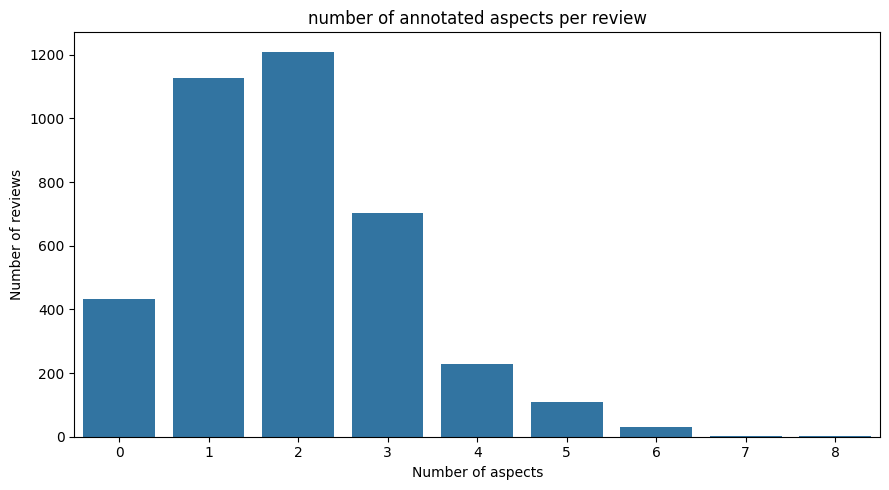

In [22]:
plt.figure(figsize=(9,5))
sns.countplot(x=labels_per_review)
plt.title("number of annotated aspects per review")
plt.xlabel("Number of aspects")
plt.ylabel("Number of reviews")

plt.tight_layout()
plt.show()

In [23]:
final_dataset = pd.concat([X.rename("Review"),Y],axis=1)
final_dataset.to_csv(PROJECT_PATH + "/dataset/final_dataset.csv",index=False,encoding="utf-8-sig")
print("Final dataset saved successfully")

Final dataset saved successfully


In [24]:
zero_count = (Y.sum(axis=1) == 0).sum()
print("Zero-annotated reviews:",zero_count)
valid_mask = Y.sum(axis=1)>0
X_model = X[valid_mask].reset_index(drop=True)
Y_model = Y.loc[valid_mask].reset_index(drop=True)
print("\nDataset for modelling:")
print("reviews:",len(X_model))
print("Labels:",Y_model.shape)
print("Average aspects:", Y_model.sum(axis=1).mean())

Zero-annotated reviews: 433

Dataset for modelling:
reviews: 3409
Labels: (3409, 9)
Average aspects: 2.144910530947492


In [25]:
!pip install iterative-stratification

In [26]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
splitter = MultilabelStratifiedShuffleSplit( n_splits=1, test_size=0.20,random_state=42)
train_idx,test_idx = next(splitter.split(X_model,Y_model))
X_train = X_model.iloc[train_idx]
X_test = X_model.iloc[test_idx]

y_train= Y_model.iloc[train_idx]
y_test = Y_model.iloc[test_idx]

print("Training reviews:", len(X_train))
print("Testing reviews", len(X_test))
print("Training labels", y_train.shape)
print("Testing labels",y_test.shape)

Training reviews: 2730
Testing reviews 679
Training labels (2730, 9)
Testing labels (679, 9)


In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1,2),min_df=2)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:",X_test_tfidf.shape)

Training matrix: (2730, 10000)
Testing matrix: (679, 10000)


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

model_Ir = OneVsRestClassifier(LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))
model_Ir.fit(X_train_tfidf,y_train)

OneVsRestClassifier(estimator=LogisticRegression(class_weight='balanced',
                                                 max_iter=1000,
                                                 random_state=42))

In [29]:
y_pred = model_Ir.predict(X_test_tfidf)
print("Prediction shape:",y_pred.shape)
print("Actual labels shape:", y_test.shape)

Prediction shape: (679, 9)
Actual labels shape: (679, 9)


In [30]:
from sklearn.metrics import(classification_report,hamming_loss,accuracy_score)

print(classification_report(y_test,y_pred,target_names=aspect_columns,zero_division=0))

              precision    recall  f1-score   support

   Direction       0.68      0.65      0.67       231
      Acting       0.87      0.85      0.86       242
       Songs       0.75      0.72      0.73       137
  Screenplay       0.86      0.79      0.82       166
       Story       0.67      0.72      0.70       155
      Camera       0.89      0.81      0.85       192
     Casting       0.69      0.70      0.69       164
         BGM       0.83      0.71      0.77        90
     Editing       0.82      0.74      0.78        85

   micro avg       0.78      0.75      0.76      1462
   macro avg       0.78      0.74      0.76      1462
weighted avg       0.78      0.75      0.76      1462
 samples avg       0.73      0.73      0.70      1462



In [31]:
print("Exact Match Accuracy:", accuracy_score(y_test,y_pred))
print("hamming loss",hamming_loss(y_test,y_pred))

Exact Match Accuracy: 0.4005891016200295
hamming loss 0.1106201930944199


In [32]:
print(classification_report(y_test,y_pred,target_names=aspect_columns,zero_division=0))

              precision    recall  f1-score   support

   Direction       0.68      0.65      0.67       231
      Acting       0.87      0.85      0.86       242
       Songs       0.75      0.72      0.73       137
  Screenplay       0.86      0.79      0.82       166
       Story       0.67      0.72      0.70       155
      Camera       0.89      0.81      0.85       192
     Casting       0.69      0.70      0.69       164
         BGM       0.83      0.71      0.77        90
     Editing       0.82      0.74      0.78        85

   micro avg       0.78      0.75      0.76      1462
   macro avg       0.78      0.74      0.76      1462
weighted avg       0.78      0.75      0.76      1462
 samples avg       0.73      0.73      0.70      1462



In [33]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test["Acting"],y_pred[:,aspect_columns.index("Acting")])
print(cm)

[[406  31]
 [ 36 206]]


In [34]:
from sklearn.metrics import confusion_matrix
import pandas as pd

confusion_results = []

for i, aspect in enumerate(aspect_columns):

    tn, fp, fn, tp = confusion_matrix(
        y_test[aspect],
        y_pred[:, i],
        labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Aspect": aspect,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

confusion_df = pd.DataFrame(confusion_results)

display(confusion_df)

,Aspect,True Negative,False Positive,False Negative,True Positive
0,Direction,377,71,80,151
1,Acting,406,31,36,206
2,Songs,510,32,39,98
3,Screenplay,491,22,35,131
4,Story,469,55,43,112
5,Camera,467,20,36,156
6,Casting,464,51,50,114
7,BGM,576,13,26,64
8,Editing,580,14,22,63


In [35]:
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier

model_svm = OneVsRestClassifier(LinearSVC(class_weight="balanced", random_state=42,max_iter=2000))
model_svm.fit(X_train_tfidf,y_train)

OneVsRestClassifier(estimator=LinearSVC(class_weight='balanced', max_iter=2000,
                                        random_state=42))

In [36]:
y_pred_svm = model_svm.predict(X_test_tfidf)
print("Prediction shape:",y_pred_svm.shape)

Prediction shape: (679, 9)


In [37]:
from sklearn.metrics import (classification_report,accuracy_score,hamming_loss,f1_score)
print("linear svm classification report")
print(classification_report(y_test,y_pred_svm,target_names=aspect_columns,zero_division=0))

linear svm classification report
              precision    recall  f1-score   support

   Direction       0.75      0.70      0.72       231
      Acting       0.87      0.86      0.87       242
       Songs       0.80      0.72      0.75       137
  Screenplay       0.88      0.81      0.84       166
       Story       0.76      0.74      0.75       155
      Camera       0.90      0.86      0.88       192
     Casting       0.74      0.69      0.71       164
         BGM       0.89      0.70      0.78        90
     Editing       0.90      0.75      0.82        85

   micro avg       0.82      0.77      0.80      1462
   macro avg       0.83      0.76      0.79      1462
weighted avg       0.83      0.77      0.80      1462
 samples avg       0.77      0.74      0.73      1462



In [38]:
print("Exact match accuracy:",accuracy_score(y_test,y_pred_svm))
print("Hamming loss:",hamming_loss(y_test,y_pred_svm))
print("micro f1:",f1_score(y_test,y_pred_svm,average="micro"))
print("macro f1:",f1_score(y_test,y_pred_svm,average="macro"))

Exact match accuracy: 0.49189985272459497
Hamming loss: 0.09441989854360988
micro f1: 0.7957522123893805
macro f1: 0.7928800162489241


In [39]:
print(classification_report(y_test,y_pred_svm,target_names=aspect_columns,zero_division=0))

              precision    recall  f1-score   support

   Direction       0.75      0.70      0.72       231
      Acting       0.87      0.86      0.87       242
       Songs       0.80      0.72      0.75       137
  Screenplay       0.88      0.81      0.84       166
       Story       0.76      0.74      0.75       155
      Camera       0.90      0.86      0.88       192
     Casting       0.74      0.69      0.71       164
         BGM       0.89      0.70      0.78        90
     Editing       0.90      0.75      0.82        85

   micro avg       0.82      0.77      0.80      1462
   macro avg       0.83      0.76      0.79      1462
weighted avg       0.83      0.77      0.80      1462
 samples avg       0.77      0.74      0.73      1462



In [40]:
direction_index = aspect_columns.index("Direction")
fn_mask=((y_test["Direction"].to_numpy()==1)&(y_pred_svm[:,direction_index]==0))
fn_indices = np.where(fn_mask)[0]
print("False Negative:",len(fn_indices))

False Negative: 69


In [41]:
for i in fn_indices[:10]:
  print("review",X_test.iloc[i])
  print("Actual direction:",y_test["Direction"].iloc[i])
  print("Prediction Direction",y_pred_svm[i,direction_index])
  print("-"*60)

review സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന് തോന്നി.
Actual direction: 1
Prediction Direction 0
------------------------------------------------------------
review സംഗീതം. അഭിനയം ക്യാമറ കലാസംവിധാനം സംവിധാനം എല്ലാം മികച്ചത്. ഫഹദ് ഫാസിൽ എന്ന നടന്റെ വില്ലൻ കഥാപത്രം ഉഗ്രൻ.
Actual direction: 1
Prediction Direction 0
------------------------------------------------------------
review ലിജോ ജോസ് സംവിധാനം ചെയ്ത വ്യത്യസ്തമായ പ്രമേയം കാഴ്ച വച്ച സിനിമ
Actual direction: 1
Prediction Direction 0
------------------------------------------------------------
review ഇന്നലെ നെറ്ഫ്ലിസ് -ൽ ഇത് കണ്ടു ആവറേജ് ഫ്ലിക്കിന് താഴെ.... 90കളിലെ കഥയും മേക്കിംഗ് ശൈലിയും..... സീരിയൽ തരം... സ് ജി യുടെ ചില സീനുകൾ നന്നായിട്ടുണ്ട്.. പ്രത്യേകിച്ച് ഹോസ്പിറ്റലിൽ വി സ് സ് ഐ .. വിശ്രമിക്കൂ സിനിമ വലിയ പരാജയമാണ്... നിതിൻ രഞ്ജി പണിക്കർ പ്ലീസ്സ് ലേലം 2 തൊടരുത്... ഒരു അപേക്ഷയാണ്. ..
Actual direction: 1
Prediction Direction 0
------------------------------------------------------------
review ശരാശരി സംവിധാനം അഭിനയം കാസ്റ്റിംഗ

In [46]:
fn_analysis = []

for i in fn_indices:
  review = X_test.iloc[i]
  fn_analysis.append({
      "Review":review,
      "Word Count": len(review.split()),
      "Character Count":len(review)
  })
  fn_analysis_df = pd.DataFrame(fn_analysis)
  display(fn_analysis_df.head(20))
  print("Average word count:",fn_analysis_df["Word Count"].mean())
  print("Median word count:",fn_analysis_df["Word Count"].median())

,Review,Word Count,Character Count
0,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്...",8,54


Average word count: 8.0
Median word count: 8.0


,Review,Word Count,Character Count
0,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്...",8,54
1,സംഗീതം. അഭിനയം ക്യാമറ കലാസംവിധാനം സംവിധാനം എല്...,14,105


Average word count: 11.0
Median word count: 11.0


,Review,Word Count,Character Count
0,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്...",8,54
1,സംഗീതം. അഭിനയം ക്യാമറ കലാസംവിധാനം സംവിധാനം എല്...,14,105
2,ലിജോ ജോസ് സംവിധാനം ചെയ്ത വ്യത്യസ്തമായ പ്രമേയം ...,9,62


Average word count: 10.333333333333334
Median word count: 9.0


... (128 outputs left out)

,Review,Word Count,Character Count
0,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്...",8,54
1,സംഗീതം. അഭിനയം ക്യാമറ കലാസംവിധാനം സംവിധാനം എല്...,14,105
2,ലിജോ ജോസ് സംവിധാനം ചെയ്ത വ്യത്യസ്തമായ പ്രമേയം ...,9,62
3,ഇന്നലെ നെറ്ഫ്ലിസ് -ൽ ഇത് കണ്ടു ആവറേജ് ഫ്ലിക്കി...,41,291
4,ശരാശരി സംവിധാനം അഭിനയം കാസ്റ്റിംഗ് എഡിറ്റിംഗ്.,5,46
5,22 ഫീമെയിൽ കോട്ടയം (2012): ഈ റിവഞ്ച് ത്രില്ലറി...,43,460
6,കഥ വളരെ മോശമായിരുന്നു. കാസ്റ്റിംഗ് സംഗീതം കുഴപ...,10,95
7,മിഥുൻ മാനുവൽ സംവിധാനം നിർവ്വഹിച്ച കുറ്റാന്വേഷണ...,7,62
8,പുതുമയുള്ള നല്ലൊരു കഥയും വ്യത്യസ്തത തോന്നിയ കഥ...,31,288
9,ഈ സിനിമയെ ഗൗരവമായി എടുക്കാൻ പറ്റാത്ത വിധം അഭിന...,13,101


Average word count: 24.514705882352942
Median word count: 16.5


,Review,Word Count,Character Count
0,"സംവിധാനം ആവറേജ് ആണ് , പക്ഷേ കഥ അപൂർണ്ണമാണെന്ന്...",8,54
1,സംഗീതം. അഭിനയം ക്യാമറ കലാസംവിധാനം സംവിധാനം എല്...,14,105
2,ലിജോ ജോസ് സംവിധാനം ചെയ്ത വ്യത്യസ്തമായ പ്രമേയം ...,9,62
3,ഇന്നലെ നെറ്ഫ്ലിസ് -ൽ ഇത് കണ്ടു ആവറേജ് ഫ്ലിക്കി...,41,291
4,ശരാശരി സംവിധാനം അഭിനയം കാസ്റ്റിംഗ് എഡിറ്റിംഗ്.,5,46
5,22 ഫീമെയിൽ കോട്ടയം (2012): ഈ റിവഞ്ച് ത്രില്ലറി...,43,460
6,കഥ വളരെ മോശമായിരുന്നു. കാസ്റ്റിംഗ് സംഗീതം കുഴപ...,10,95
7,മിഥുൻ മാനുവൽ സംവിധാനം നിർവ്വഹിച്ച കുറ്റാന്വേഷണ...,7,62
8,പുതുമയുള്ള നല്ലൊരു കഥയും വ്യത്യസ്തത തോന്നിയ കഥ...,31,288
9,ഈ സിനിമയെ ഗൗരവമായി എടുക്കാൻ പറ്റാത്ത വിധം അഭിന...,13,101


Average word count: 24.347826086956523
Median word count: 16.0


In [47]:
tp_mask = (
    (y_test["Direction"].to_numpy() == 1) &
    (y_pred_svm[:, direction_index] == 1)
)

tp_indices = np.where(tp_mask)[0]

tp_word_counts = [
    len(X_test.iloc[i].split())
    for i in tp_indices
]

fn_word_counts = [
    len(X_test.iloc[i].split())
    for i in fn_indices
]

print("True Positive average:",
      sum(tp_word_counts) / len(tp_word_counts))

print("False Negative average:",
      sum(fn_word_counts) / len(fn_word_counts))

True Positive average: 29.61111111111111
False Negative average: 24.347826086956523


In [49]:
direction_model = model_svm.estimators_[0]
feature_names = tfidf.get_feature_names_out()
top_indices = direction_model.coef_[0].argsort()[-20:][::-1]
for index in top_indices:
  print(feature_names[index],
        direction_model.coef_[0][index])

യകൻ 4.696162534588701
നവ 4.050741666629976
യകന 3.1100226401937014
ഡയറക 2.071903509622805
വളര നല 2.049119476595428
കഥ രക 1.974658636246429
ഷൻ 1.68331018280332
ശശ 1.61490371362673
ജനകമ ഒര 1.6130218201290052
ലർത 1.5223711837787137
കൾ കച 1.4244880458409614
കവ 1.3818608602143276
നല പട 1.3301217182062606
ങള ഒര 1.3075051553276538
ആകർഷകവ 1.298392893363687
കഥയ ആഴ 1.2800737224332184
നയ എഡ 1.2551999456465197
അപര തമ 1.2538217251135864
രഞ അഭ 1.234683665622153
കച നത 1.2232324748391652


In [50]:
for word in [
    "സംവിധാനം",
    "സംവിധാനം ചെയ്ത",
    "സംവിധായകൻ",
    "ഡയറക്ഷൻ"
]:
    print(
        word,
        "->",
        tfidf.build_analyzer()(word)
    )

സംവിധാനം -> []
സംവിധാനം ചെയ്ത -> []
സംവിധായകൻ -> ['യകൻ']
ഡയറക്ഷൻ -> ['ഡയറക', 'ഷൻ', 'ഡയറക ഷൻ']


In [51]:
import re

text = "സംവിധാനം ചെയ്ത സിനിമ"

print("Original text:", text)

print("Default token pattern:")
print(re.findall(r"(?u)\b\w\w+\b", text))

Original text: സംവിധാനം ചെയ്ത സിനിമ
Default token pattern:
[]


In [52]:
import re

malayalam_pattern = re.compile(
    r'[\u0D00-\u0D7F]+'
)

text = "സംവിധാനം ചെയ്ത സിനിമ"

tokens = malayalam_pattern.findall(text)

print(tokens)

['സംവിധാനം', 'ചെയ്ത', 'സിനിമ']


In [53]:
def malayalam_tokenizer(text):
    return re.findall(r'[\u0D00-\u0D7F]+', str(text))

tfidf_ml = TfidfVectorizer(
    tokenizer=malayalam_tokenizer,
    token_pattern=None,
    lowercase=False,
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf_ml = tfidf_ml.fit_transform(X_train)
X_test_tfidf_ml = tfidf_ml.transform(X_test)

print("Training matrix:", X_train_tfidf_ml.shape)
print("Testing matrix:", X_test_tfidf_ml.shape)
print("Recognized words:", tfidf_ml.build_analyzer()("സംവിധാനം ചെയ്ത സിനിമ"))

Training matrix: (2730, 10000)
Testing matrix: (679, 10000)
Recognized words: ['സംവിധാനം', 'ചെയ്ത', 'സിനിമ', 'സംവിധാനം ചെയ്ത', 'ചെയ്ത സിനിമ']


In [54]:
model_lr_ml = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

model_lr_ml.fit(X_train_tfidf_ml, y_train)

y_pred_lr_ml = model_lr_ml.predict(X_test_tfidf_ml)

print("New Logistic Regression model trained!")
print("Prediction shape:", y_pred_lr_ml.shape)

New Logistic Regression model trained!
Prediction shape: (679, 9)


In [55]:
from sklearn.metrics import (
    accuracy_score,
    hamming_loss,
    f1_score,
    classification_report
)

print("Exact Match Accuracy:",
      accuracy_score(y_test, y_pred_lr_ml))

print("Hamming Loss:",
      hamming_loss(y_test, y_pred_lr_ml))

print("Micro F1:",
      f1_score(y_test, y_pred_lr_ml, average="micro"))

print("Macro F1:",
      f1_score(y_test, y_pred_lr_ml, average="macro"))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_lr_ml,
    target_names=aspect_columns,
    zero_division=0
))

Exact Match Accuracy: 0.5449189985272459
Hamming Loss: 0.0757650139093438
Micro F1: 0.8333933069449442
Macro F1: 0.8296113680988175

Classification Report:

              precision    recall  f1-score   support

   Direction       0.86      0.80      0.83       231
      Acting       0.82      0.84      0.83       242
       Songs       0.93      0.82      0.87       137
  Screenplay       0.90      0.79      0.84       166
       Story       0.87      0.73      0.79       155
      Camera       0.95      0.83      0.89       192
     Casting       0.87      0.76      0.81       164
         BGM       0.91      0.77      0.83        90
     Editing       0.86      0.71      0.77        85

   micro avg       0.88      0.79      0.83      1462
   macro avg       0.88      0.78      0.83      1462
weighted avg       0.88      0.79      0.83      1462
 samples avg       0.83      0.79      0.79      1462



In [56]:
model_svm_ml = OneVsRestClassifier(
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=2000
    )
)

model_svm_ml.fit(X_train_tfidf_ml, y_train)

y_pred_svm_ml = model_svm_ml.predict(X_test_tfidf_ml)

print("New SVM model trained!")
print("Prediction shape:", y_pred_svm_ml.shape)

New SVM model trained!
Prediction shape: (679, 9)


In [57]:
print("Exact Match Accuracy:",
      accuracy_score(y_test, y_pred_svm_ml))

print("Hamming Loss:",
      hamming_loss(y_test, y_pred_svm_ml))

print("Micro F1:",
      f1_score(y_test, y_pred_svm_ml, average="micro"))

print("Macro F1:",
      f1_score(y_test, y_pred_svm_ml, average="macro"))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_svm_ml,
    target_names=aspect_columns,
    zero_division=0
))

Exact Match Accuracy: 0.6347569955817378
Hamming Loss: 0.06365570283096056
Micro F1: 0.8612201212986086
Macro F1: 0.8589897397646474

Classification Report:

              precision    recall  f1-score   support

   Direction       0.91      0.83      0.87       231
      Acting       0.87      0.82      0.84       242
       Songs       0.96      0.82      0.89       137
  Screenplay       0.88      0.83      0.85       166
       Story       0.87      0.77      0.82       155
      Camera       0.94      0.90      0.92       192
     Casting       0.90      0.83      0.86       164
         BGM       0.92      0.80      0.86        90
     Editing       0.89      0.78      0.83        85

   micro avg       0.90      0.83      0.86      1462
   macro avg       0.90      0.82      0.86      1462
weighted avg       0.90      0.83      0.86      1462
 samples avg       0.85      0.82      0.82      1462



In [58]:
story_index = aspect_columns.index("Story")

story_fn = np.where(
    (y_test["Story"].to_numpy() == 1) &
    (y_pred_svm_ml[:, story_index] == 0)
)[0]

print("Story false negatives:", len(story_fn))

for i in story_fn[:5]:
    print("\nReview:", X_test.iloc[i])

Story false negatives: 36

Review: ജയസൂര്യയുടെയും ജാഫർ ഇടുക്കിയുടെയും മികച്ച പ്രകടനത്തിൽ നിന്ന് വിചിത്രമായ തലക്കെട്ടുള്ള ഈശോ പ്രയോജനം നേടുന്നു, പക്ഷേ കഥപറച്ചിൽ ശൈലി ഒരു വലിയ പരാജയമാണ്. സ്‌ക്രിപ്റ്റിൽ ഒരു ചെറിയ സസ്പെൻസ് പോലും ഇല്ല, മാത്രമല്ല പ്ലോട്ടിലെ ഓരോ ട്വിസ്റ്റും തിരിവും മനസ്സിലാക്കാൻ ശരാശരി ത്രില്ലർ പ്രേക്ഷകന് കഴിയണം.

Review: സ്റ്റോറി ഡയറക്ഷൻ ആക്ടിങ് സിനിമേട്ടോഗ്രാഫി വീഡിയോഗ്രാഫി എല്ലാം നല്ലത് ആണ്.

Review: റാണി പത്മിനി (2015) ഛായാഗ്രഹണം മങ്ങിയതും പ്രചോദകരമല്ലാത്തതും, ശ്രദ്ധേയമല്ലാത്ത ഫ്രെയിമിംഗും ലൈറ്റിംഗും ഉള്ളതായി തോന്നുന്നു. പ്രധാന അഭിനേതാക്കളായ മഞ്ജു വാര്യരും റിമ കല്ലിങ്കലും തങ്ങളുടെ കഥാപാത്രങ്ങൾക്ക് ആഴം കൊണ്ടുവരുന്നതിൽ പരാജയപ്പെടുന്നു. കഥ ക്ലീഷേയും പ്രവചിക്കാവുന്നതുമാണ്, മാത്രമല്ല അത് പരാജയപ്പെടുകയും ചെയ്യുന്നു. അർഥവത്തായ പ്രമേയങ്ങൾ പര്യവേക്ഷണം ചെയ്യാൻ അത് സജ്ജീകരിച്ചിരിക്കുന്നു. ആഷിക് അബുവിന്റെ സംവിധാനം അലസവും പ്രചോദനമില്ലാത്തതുമാണെന്ന് തോന്നുന്നു, കൂടാതെ ആഖ്യാനത്തിലേക്ക് ഊർജം പകരുന്നതിൽ അദ്ദേഹം പരാജയപ്പെട്ടു. ശ്യാം പുഷ്‌കരന്റെ തിരക്കഥ, അനാവശ്യമായ ഉപകഥകളും രംഗങ്ങളും കൊണ്ട്

In [59]:
for i in story_fn[:5]:
    print("\nReview:", X_test.iloc[i])
    print("Actual labels:", y_test.iloc[i].to_dict())


Review: ജയസൂര്യയുടെയും ജാഫർ ഇടുക്കിയുടെയും മികച്ച പ്രകടനത്തിൽ നിന്ന് വിചിത്രമായ തലക്കെട്ടുള്ള ഈശോ പ്രയോജനം നേടുന്നു, പക്ഷേ കഥപറച്ചിൽ ശൈലി ഒരു വലിയ പരാജയമാണ്. സ്‌ക്രിപ്റ്റിൽ ഒരു ചെറിയ സസ്പെൻസ് പോലും ഇല്ല, മാത്രമല്ല പ്ലോട്ടിലെ ഓരോ ട്വിസ്റ്റും തിരിവും മനസ്സിലാക്കാൻ ശരാശരി ത്രില്ലർ പ്രേക്ഷകന് കഴിയണം.
Actual labels: {'Direction': 0, 'Acting': 0, 'Songs': 0, 'Screenplay': 1, 'Story': 1, 'Camera': 0, 'Casting': 0, 'BGM': 0, 'Editing': 0}

Review: സ്റ്റോറി ഡയറക്ഷൻ ആക്ടിങ് സിനിമേട്ടോഗ്രാഫി വീഡിയോഗ്രാഫി എല്ലാം നല്ലത് ആണ്.
Actual labels: {'Direction': 1, 'Acting': 1, 'Songs': 0, 'Screenplay': 0, 'Story': 1, 'Camera': 1, 'Casting': 0, 'BGM': 0, 'Editing': 0}

Review: റാണി പത്മിനി (2015) ഛായാഗ്രഹണം മങ്ങിയതും പ്രചോദകരമല്ലാത്തതും, ശ്രദ്ധേയമല്ലാത്ത ഫ്രെയിമിംഗും ലൈറ്റിംഗും ഉള്ളതായി തോന്നുന്നു. പ്രധാന അഭിനേതാക്കളായ മഞ്ജു വാര്യരും റിമ കല്ലിങ്കലും തങ്ങളുടെ കഥാപാത്രങ്ങൾക്ക് ആഴം കൊണ്ടുവരുന്നതിൽ പരാജയപ്പെടുന്നു. കഥ ക്ലീഷേയും പ്രവചിക്കാവുന്നതുമാണ്, മാത്രമല്ല അത് പരാജയപ്പെടുകയും ചെയ്യുന്നു. അർഥവത്തായ പ്രമേയങ്

In [60]:
story_model = model_svm_ml.estimators_[story_index]

story_coefficients = story_model.coef_.flatten()

story_feature_names = tfidf_ml.get_feature_names_out()

top_story_indices = np.argsort(story_coefficients)[-20:][::-1]

for i in top_story_indices:
    print(
        story_feature_names[i],
        round(story_coefficients[i], 3)
    )

കഥ 8.071
കഥയും 5.908
കഥയുടെ 2.633
പ്ലോട്ട് 2.425
കഥയാണ് 2.38
കഥയിൽ 2.32
കഥയ്ക്ക് 2.163
കഥാതന്തു 1.882
കഥയെ 1.817
സ്റ്റോറി 1.789
കഥയും തിരക്കഥയും 1.646
തീം 1.595
കഥ തിരക്കഥ 1.542
ലൈൻ 1.487
തമാശകൾ 1.468
പുതുമ 1.446
കുടുംബ 1.437
സ്റ്റോറി ലൈൻ 1.359
കഥാ 1.309
ഒരിക്കൽ 1.205


In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=10000,
    min_df=2
)

X_train_char = char_tfidf.fit_transform(X_train)
X_test_char = char_tfidf.transform(X_test)

print("Training matrix:", X_train_char.shape)
print("Testing matrix:", X_test_char.shape)

Training matrix: (2730, 10000)
Testing matrix: (679, 10000)


In [62]:
model_svm_char = OneVsRestClassifier(
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=2000
    )
)

model_svm_char.fit(X_train_char, y_train)

y_pred_svm_char = model_svm_char.predict(X_test_char)

print("Character-level SVM trained!")
print("Prediction shape:", y_pred_svm_char.shape)

Character-level SVM trained!
Prediction shape: (679, 9)


In [63]:
print("Exact Match Accuracy:",
      accuracy_score(y_test, y_pred_svm_char))

print("Hamming Loss:",
      hamming_loss(y_test, y_pred_svm_char))

print("Micro F1:",
      f1_score(y_test, y_pred_svm_char, average="micro"))

print("Macro F1:",
      f1_score(y_test, y_pred_svm_char, average="macro"))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_svm_char,
    target_names=aspect_columns,
    zero_division=0
))

Exact Match Accuracy: 0.6362297496318114
Hamming Loss: 0.05956471935853379
Micro F1: 0.8739612188365651
Macro F1: 0.8702446770672051

Classification Report:

              precision    recall  f1-score   support

   Direction       0.91      0.86      0.88       231
      Acting       0.89      0.86      0.88       242
       Songs       0.95      0.88      0.92       137
  Screenplay       0.89      0.90      0.90       166
       Story       0.79      0.81      0.80       155
      Camera       0.94      0.93      0.94       192
     Casting       0.83      0.81      0.82       164
         BGM       0.91      0.88      0.89        90
     Editing       0.82      0.80      0.81        85

   micro avg       0.88      0.86      0.87      1462
   macro avg       0.88      0.86      0.87      1462
weighted avg       0.89      0.86      0.87      1462
 samples avg       0.84      0.85      0.83      1462

